# Clustering Jerárquico (Hierarchical Clustering)

## ¿Cuál es el objetivo del Clustering Jerárquico?

El **Clustering Jerárquico** es un algoritmo de aprendizaje **no supervisado** que agrupa datos en una **jerarquía de clusters** (grupos anidados), creando una estructura tipo árbol llamada **dendrograma**.

A diferencia de K-Means, donde debemos especificar el número de clusters $k$ de antemano, el clustering jerárquico construye **toda la jerarquía** de agrupaciones y podemos elegir el nivel de detalle que queramos después.

Existen dos enfoques:

| Enfoque | Nombre | Dirección | Descripción |
|---|---|---|---|
| **Bottom-up** | **Aglomerativo** | ↑ De abajo hacia arriba | Empieza con cada punto como su propio cluster y los va **fusionando** |
| **Top-down** | **Divisivo** | ↓ De arriba hacia abajo | Empieza con un solo cluster y lo va **dividiendo** |

El enfoque **aglomerativo** es el más utilizado y el que implementaremos.

**Algoritmo Aglomerativo (idea intuitiva):**

1. Cada punto empieza como su propio cluster individual
2. Encontrar los **dos clusters más cercanos**
3. **Fusionarlos** en un solo cluster
4. Repetir pasos 2-3 hasta que quede **un solo cluster**

El resultado es un árbol (dendrograma) que muestra **qué se fusionó con qué y a qué distancia**.

**Supongamos un conjunto de datos simple**

Tomemos 6 puntos en 2D:

| Punto | $x_1$ | $x_2$ |
|-------|-------|-------|
| A     | 1     | 1     |
| B     | 1.5   | 1.5   |
| C     | 5     | 5     |
| D     | 5.5   | 5.5   |
| E     | 3     | 4     |
| F     | 3.5   | 3.5   |

A simple vista, A y B están cerca (un grupo), C y D están cerca (otro grupo), y E y F están en medio. ¿Cómo organiza esto el algoritmo?

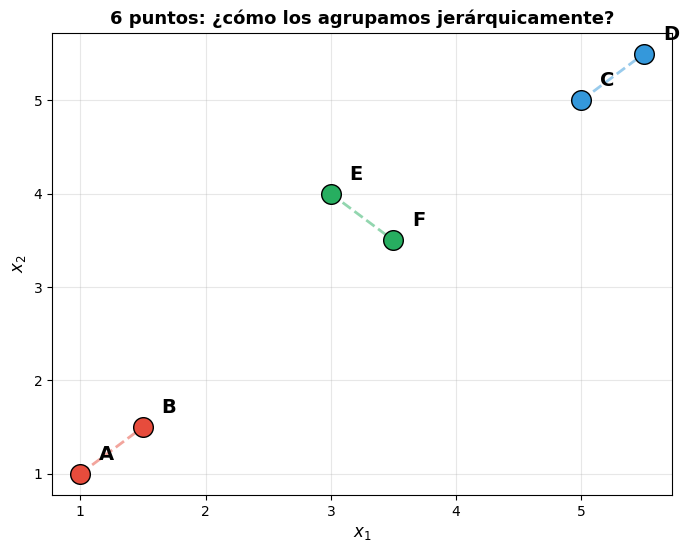

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Datos de ejemplo
points = np.array([[1, 1], [1.5, 1.5], [5, 5], [5.5, 5.5], [3, 4], [3.5, 3.5]])
labels = ['A', 'B', 'C', 'D', 'E', 'F']

plt.figure(figsize=(8, 6))
colors = ['#e74c3c', '#e74c3c', '#3498db', '#3498db', '#27ae60', '#27ae60']
for i, (p, l) in enumerate(zip(points, labels)):
    plt.scatter(p[0], p[1], c=colors[i], s=200, edgecolors='k', zorder=5)
    plt.annotate(l, (p[0]+0.15, p[1]+0.15), fontsize=14, fontweight='bold')

# Dibujar distancias cercanas
for i, j, col in [(0,1,'#e74c3c'), (2,3,'#3498db'), (4,5,'#27ae60')]:
    plt.plot([points[i][0], points[j][0]], [points[i][1], points[j][1]],
             '--', color=col, alpha=0.5, lw=2)

plt.xlabel('$x_1$', fontsize=12)
plt.ylabel('$x_2$', fontsize=12)
plt.title('6 puntos: ¿cómo los agrupamos jerárquicamente?', fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.show()

## ¿Cómo decide el algoritmo qué clusters fusionar?

En cada paso, el algoritmo fusiona los **dos clusters más cercanos**. Pero cuando un cluster tiene más de un punto, ¿cómo medimos la distancia entre dos clusters? Aquí es donde entran los **criterios de enlace** (linkage).

Necesitamos la demostración matemática para entender esto en detalle.

## Demostración Matemática

### Paso 1: Distancia entre puntos

La base de todo es la distancia entre dos puntos. La más común es la **distancia euclidiana**:

$$
d(\mathbf{a}, \mathbf{b}) = \sqrt{\sum_{i=1}^{n}(a_i - b_i)^2} = \|\mathbf{a} - \mathbf{b}\|_2
$$

Para nuestros datos de ejemplo:

$$
d(A, B) = \sqrt{(1-1.5)^2 + (1-1.5)^2} = \sqrt{0.25 + 0.25} = \sqrt{0.5} \approx 0.707
$$

Con $n$ puntos, construimos una **matriz de distancias** de tamaño $n \times n$:

$$
D_{ij} = d(\mathbf{x}_i, \mathbf{x}_j)
$$

Esta matriz es simétrica ($D_{ij} = D_{ji}$) y tiene ceros en la diagonal ($D_{ii} = 0$).

### Paso 2: Criterios de Enlace (Linkage)

Cuando fusionamos puntos individuales en clusters, necesitamos definir cómo medir la distancia entre **dos conjuntos de puntos**. Sean $C_i$ y $C_j$ dos clusters:

#### Single Linkage (Enlace Simple)

Distancia = la **mínima** distancia entre cualquier par de puntos:

$$
d_{\text{single}}(C_i, C_j) = \min_{\mathbf{a} \in C_i, \; \mathbf{b} \in C_j} d(\mathbf{a}, \mathbf{b})
$$

- **Ventaja**: puede detectar clusters de formas irregulares (cadenas)
- **Desventaja**: efecto "cadena" — puede fusionar clusters que no deberían fusionarse si hay un punto "puente" entre ellos

#### Complete Linkage (Enlace Completo)

Distancia = la **máxima** distancia entre cualquier par de puntos:

$$
d_{\text{complete}}(C_i, C_j) = \max_{\mathbf{a} \in C_i, \; \mathbf{b} \in C_j} d(\mathbf{a}, \mathbf{b})
$$

- **Ventaja**: produce clusters compactos y esféricos
- **Desventaja**: sensible a outliers

#### Average Linkage (Enlace Promedio)

Distancia = el **promedio** de todas las distancias entre pares:

$$
d_{\text{average}}(C_i, C_j) = \frac{1}{|C_i| \cdot |C_j|} \sum_{\mathbf{a} \in C_i} \sum_{\mathbf{b} \in C_j} d(\mathbf{a}, \mathbf{b})
$$

- **Ventaja**: compromiso entre single y complete, más robusto
- **Desventaja**: más costoso computacionalmente

#### Ward's Method (Método de Ward)

Minimiza el **incremento en la varianza total** al fusionar dos clusters. Fusiona los clusters cuya unión produzca el menor aumento en la suma de cuadrados dentro del cluster (WCSS):

$$
d_{\text{ward}}(C_i, C_j) = \sqrt{\frac{2 |C_i| |C_j|}{|C_i| + |C_j|}} \|\boldsymbol{\mu}_i - \boldsymbol{\mu}_j\|
$$

Donde $\boldsymbol{\mu}_i$ y $\boldsymbol{\mu}_j$ son los centroides de los clusters.

- **Ventaja**: produce clusters de tamaños similares y bien separados
- **Desventaja**: asume clusters esféricos

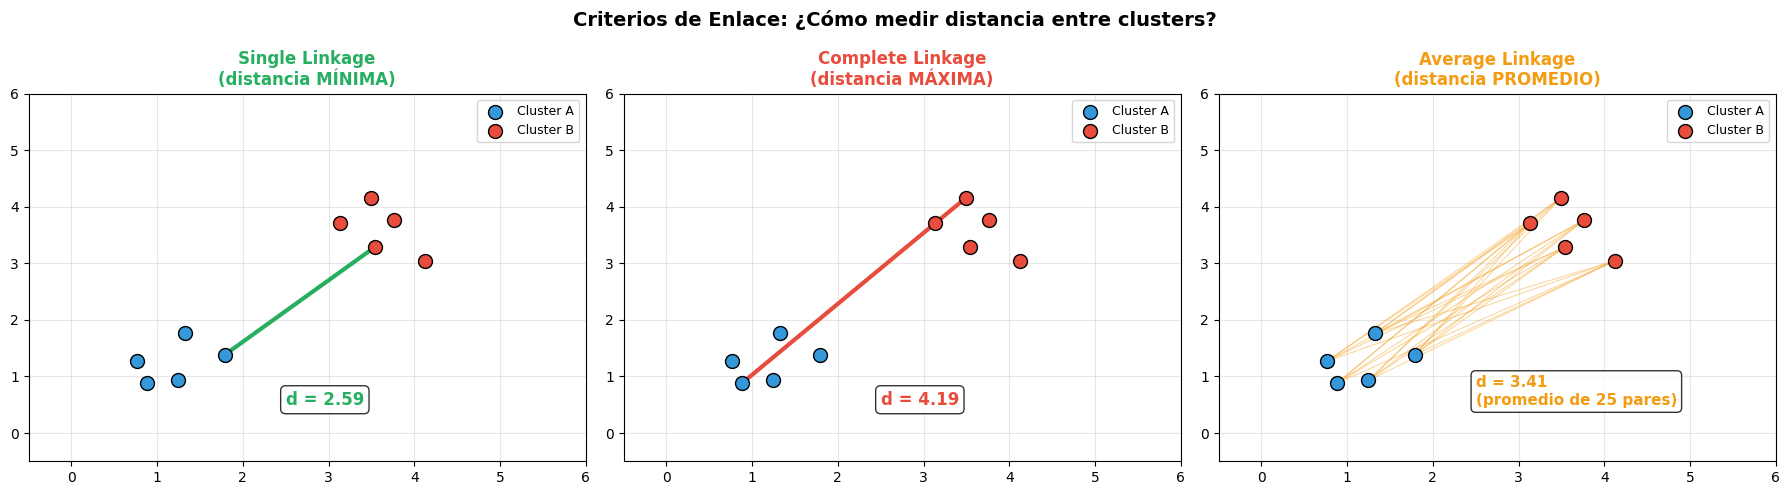

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Visualizar los 3 criterios de enlace
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

np.random.seed(42)
cluster_a = np.random.randn(5, 2) * 0.5 + np.array([1, 1])
cluster_b = np.random.randn(5, 2) * 0.5 + np.array([4, 4])

titles = ['Single Linkage\n(distancia MÍNIMA)', 'Complete Linkage\n(distancia MÁXIMA)', 'Average Linkage\n(distancia PROMEDIO)']
colors_link = ['#27ae60', '#e74c3c', '#f39c12']

for ax, title, color in zip(axes, titles, colors_link):
    ax.scatter(cluster_a[:, 0], cluster_a[:, 1], c='#3498db', s=100, edgecolors='k', zorder=5, label='Cluster A')
    ax.scatter(cluster_b[:, 0], cluster_b[:, 1], c='#e74c3c', s=100, edgecolors='k', zorder=5, label='Cluster B')
    ax.set_title(title, fontsize=12, fontweight='bold', color=color)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)
    ax.set_xlim(-0.5, 6)
    ax.set_ylim(-0.5, 6)

# Single: dibujar la distancia mínima
min_d = np.inf
min_pair = None
for a in cluster_a:
    for b in cluster_b:
        d = np.linalg.norm(a - b)
        if d < min_d:
            min_d = d
            min_pair = (a, b)
axes[0].plot([min_pair[0][0], min_pair[1][0]], [min_pair[0][1], min_pair[1][1]],
             '-', color='#27ae60', lw=3, zorder=4)
axes[0].text(2.5, 0.5, f'd = {min_d:.2f}', fontsize=12, color='#27ae60', fontweight='bold',
             bbox=dict(facecolor='white', alpha=0.8, boxstyle='round'))

# Complete: dibujar la distancia máxima
max_d = 0
max_pair = None
for a in cluster_a:
    for b in cluster_b:
        d = np.linalg.norm(a - b)
        if d > max_d:
            max_d = d
            max_pair = (a, b)
axes[1].plot([max_pair[0][0], max_pair[1][0]], [max_pair[0][1], max_pair[1][1]],
             '-', color='#e74c3c', lw=3, zorder=4)
axes[1].text(2.5, 0.5, f'd = {max_d:.2f}', fontsize=12, color='#e74c3c', fontweight='bold',
             bbox=dict(facecolor='white', alpha=0.8, boxstyle='round'))

# Average: dibujar todas las distancias
total_d = 0
count = 0
for a in cluster_a:
    for b in cluster_b:
        d = np.linalg.norm(a - b)
        total_d += d
        count += 1
        axes[2].plot([a[0], b[0]], [a[1], b[1]], '-', color='#f39c12', lw=0.8, alpha=0.4, zorder=3)
avg_d = total_d / count
axes[2].text(2.5, 0.5, f'd = {avg_d:.2f}\n(promedio de {count} pares)', fontsize=11,
             color='#f39c12', fontweight='bold',
             bbox=dict(facecolor='white', alpha=0.8, boxstyle='round'))

plt.suptitle('Criterios de Enlace: ¿Cómo medir distancia entre clusters?', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Paso 3: El Dendrograma

El resultado del clustering jerárquico es un **dendrograma** — un diagrama de árbol que muestra:

- **Eje horizontal**: los puntos de datos (hojas del árbol)
- **Eje vertical**: la distancia a la que se fusionaron los clusters
- **Cada "U"**: una fusión de dos clusters

Para obtener $k$ clusters, cortamos el dendrograma a cierta altura con una **línea horizontal**. Los clusters son las ramas que cruza esa línea.

**Criterio para elegir el número de clusters:** Buscar el **salto más grande** en la distancia de fusión — esto indica que estamos fusionando clusters que realmente son diferentes.

### Paso 4: Algoritmo Completo

---

**Entrada:** $n$ puntos $\{\mathbf{x}_1, \dots, \mathbf{x}_n\}$, criterio de enlace $d_{\text{link}}$

**Inicialización:** Cada punto es su propio cluster: $C_i = \{\mathbf{x}_i\}$ para $i = 1, \dots, n$

**Calcular** la matriz de distancias $D \in \mathbb{R}^{n \times n}$

**Para** $\text{paso} = 1, 2, \dots, n-1$:

$\quad$ 1. Encontrar el par $(i^*, j^*)$ con la **menor distancia**: $(i^*, j^*) = \arg\min_{i \neq j} D_{ij}$

$\quad$ 2. **Registrar** la fusión: $(C_{i^*}, C_{j^*}, D_{i^*j^*})$

$\quad$ 3. **Fusionar**: $C_{\text{nuevo}} = C_{i^*} \cup C_{j^*}$

$\quad$ 4. **Actualizar** la matriz de distancias: calcular $d_{\text{link}}(C_{\text{nuevo}}, C_k)$ para todos los clusters restantes $C_k$

$\quad$ 5. **Eliminar** $C_{i^*}$ y $C_{j^*}$ de la lista, agregar $C_{\text{nuevo}}$

**Retornar:** historial de fusiones (dendrograma)

---

**Complejidad:**
- **Tiempo**: $O(n^3)$ en general, $O(n^2 \log n)$ con optimizaciones
- **Espacio**: $O(n^2)$ para la matriz de distancias

### Ejemplo numérico

Apliquemos el algoritmo con **single linkage** a nuestros 6 puntos.

**Paso 0: Matriz de distancias inicial**

| | A(1,1) | B(1.5,1.5) | C(5,5) | D(5.5,5.5) | E(3,4) | F(3.5,3.5) |
|---|---|---|---|---|---|---|
| **A** | 0 | 0.71 | 5.66 | 6.36 | 3.61 | 3.54 |
| **B** | | 0 | 4.95 | 5.66 | 2.92 | 2.83 |
| **C** | | | 0 | 0.71 | 2.24 | 2.12 |
| **D** | | | | 0 | 2.92 | 2.83 |
| **E** | | | | | 0 | 0.71 |
| **F** | | | | | | 0 |

**Fusión 1:** Mínima = 0.71 → fusionar **A-B** (distancia 0.71)

**Fusión 2:** Mínima = 0.71 → fusionar **C-D** (distancia 0.71)

**Fusión 3:** Mínima = 0.71 → fusionar **E-F** (distancia 0.71)

**Fusión 4:** Mínima entre clusters {AB}, {CD}, {EF} → fusionar **{EF} con {CD}** (distancia 2.12, la mínima entre F y C)

**Fusión 5:** Fusionar **{AB} con {CDEF}** → un solo cluster

In [3]:
import numpy as np

# Ejemplo numérico paso a paso
points = np.array([[1, 1], [1.5, 1.5], [5, 5], [5.5, 5.5], [3, 4], [3.5, 3.5]])
labels = ['A', 'B', 'C', 'D', 'E', 'F']

# Calcular matriz de distancias
n = len(points)
dist_matrix = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        dist_matrix[i, j] = np.linalg.norm(points[i] - points[j])

print("MATRIZ DE DISTANCIAS INICIAL")
print("=" * 55)
header = "     " + "  ".join(f"{l:>6s}" for l in labels)
print(header)
for i in range(n):
    row = f"  {labels[i]}  "
    for j in range(n):
        if j < i:
            row += f"{'':>8s}"
        else:
            row += f"{dist_matrix[i,j]:>7.2f} "
    print(row)

print("\n" + "=" * 55)
print("FUSIONES (Single Linkage)")
print("=" * 55)

# Algoritmo aglomerativo (single linkage)
clusters = {i: [i] for i in range(n)}
active = set(range(n))
merge_history = []

for step in range(n - 1):
    # Encontrar par más cercano
    min_dist = np.inf
    merge_pair = None
    for ci in active:
        for cj in active:
            if ci >= cj:
                continue
            # Single linkage: min distancia entre puntos
            d = min(dist_matrix[a, b] for a in clusters[ci] for b in clusters[cj])
            if d < min_dist:
                min_dist = d
                merge_pair = (ci, cj)

    ci, cj = merge_pair
    label_ci = ','.join(labels[p] for p in sorted(clusters[ci]))
    label_cj = ','.join(labels[p] for p in sorted(clusters[cj]))

    # Fusionar
    new_id = n + step
    clusters[new_id] = clusters[ci] + clusters[cj]
    active.remove(ci)
    active.remove(cj)
    active.add(new_id)

    label_new = ','.join(labels[p] for p in sorted(clusters[new_id]))
    merge_history.append((ci, cj, min_dist, len(clusters[new_id])))

    print(f"\nFusión {step+1}: {{{label_ci}}} + {{{label_cj}}} → {{{label_new}}}  (distancia = {min_dist:.2f})")

MATRIZ DE DISTANCIAS INICIAL
          A       B       C       D       E       F
  A     0.00    0.71    5.66    6.36    3.61    3.54 
  B             0.00    4.95    5.66    2.92    2.83 
  C                     0.00    0.71    2.24    2.12 
  D                             0.00    2.92    2.83 
  E                                     0.00    0.71 
  F                                             0.00 

FUSIONES (Single Linkage)

Fusión 1: {A} + {B} → {A,B}  (distancia = 0.71)

Fusión 2: {C} + {D} → {C,D}  (distancia = 0.71)

Fusión 3: {E} + {F} → {E,F}  (distancia = 0.71)

Fusión 4: {C,D} + {E,F} → {C,D,E,F}  (distancia = 2.12)

Fusión 5: {A,B} + {C,D,E,F} → {A,B,C,D,E,F}  (distancia = 2.83)


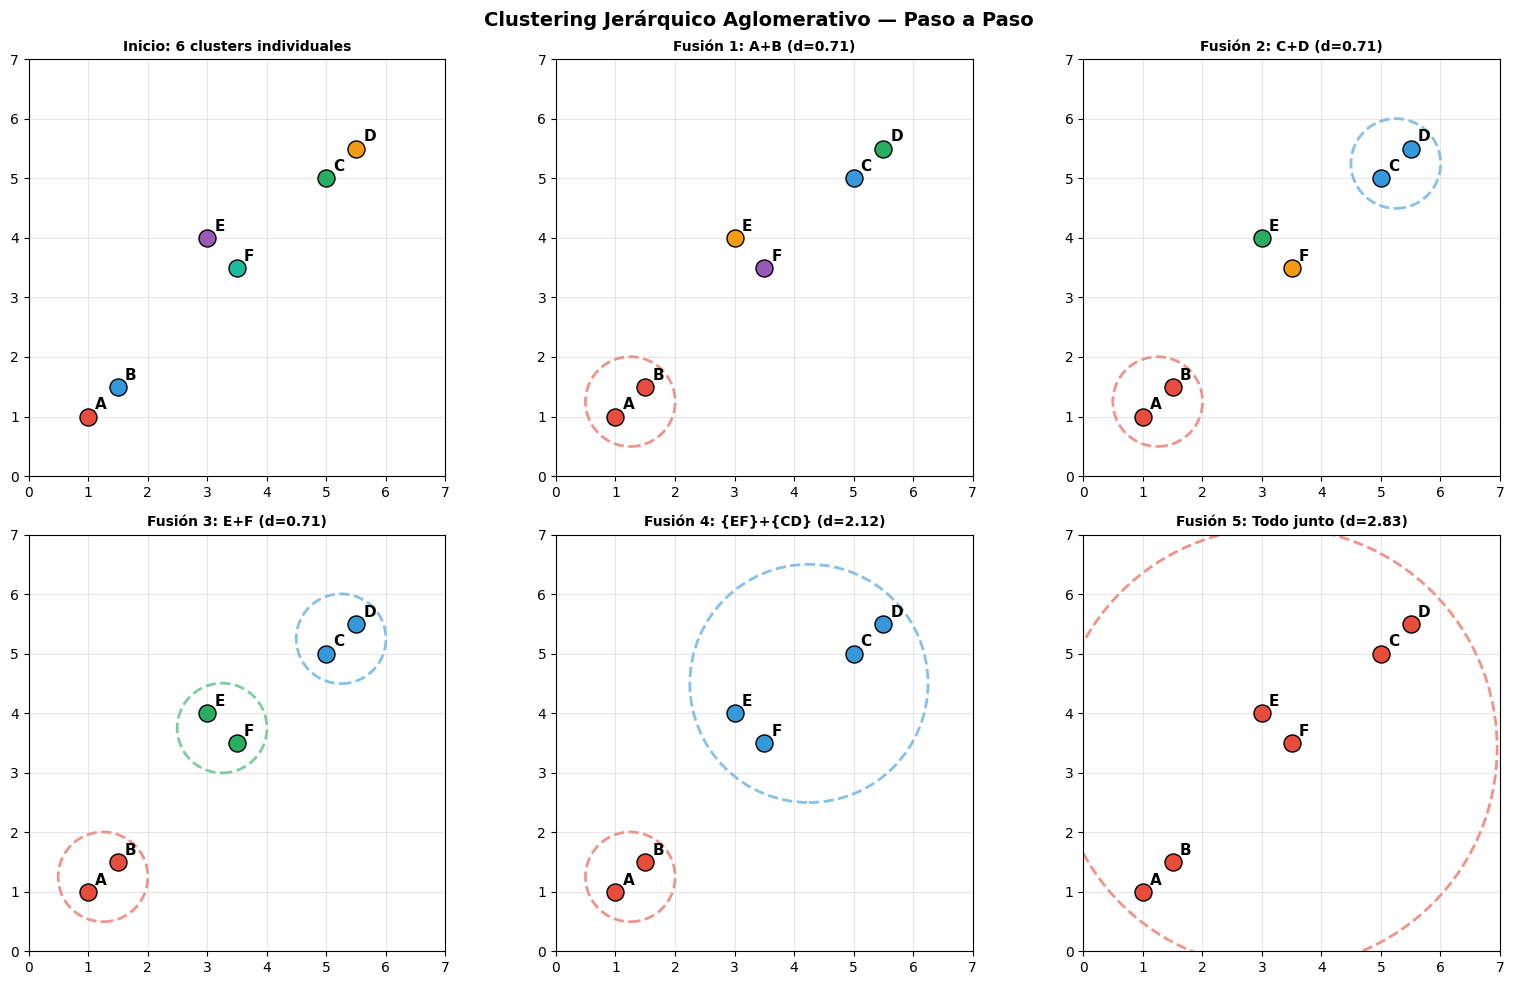

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Visualizar las fusiones paso a paso
points = np.array([[1, 1], [1.5, 1.5], [5, 5], [5.5, 5.5], [3, 4], [3.5, 3.5]])
labels = ['A', 'B', 'C', 'D', 'E', 'F']

# Estados de las fusiones (single linkage)
fusion_states = [
    # (lista de clusters, título)
    ([[0],[1],[2],[3],[4],[5]], 'Inicio: 6 clusters individuales'),
    ([[0,1],[2],[3],[4],[5]], 'Fusión 1: A+B (d=0.71)'),
    ([[0,1],[2,3],[4],[5]], 'Fusión 2: C+D (d=0.71)'),
    ([[0,1],[2,3],[4,5]], 'Fusión 3: E+F (d=0.71)'),
    ([[0,1],[2,3,4,5]], 'Fusión 4: {EF}+{CD} (d=2.12)'),
    ([[0,1,2,3,4,5]], 'Fusión 5: Todo junto (d=2.83)'),
]

color_map = ['#e74c3c', '#3498db', '#27ae60', '#f39c12', '#9b59b6', '#1abc9c']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (clusters_state, title) in zip(axes.flat, fusion_states):
    for ci, cluster in enumerate(clusters_state):
        color = color_map[ci % len(color_map)]
        for idx in cluster:
            ax.scatter(points[idx][0], points[idx][1], c=color, s=150, edgecolors='k', zorder=5)
            ax.annotate(labels[idx], (points[idx][0]+0.12, points[idx][1]+0.12),
                       fontsize=11, fontweight='bold')

        # Dibujar envolvente del cluster si tiene más de 1 punto
        if len(cluster) > 1:
            pts = points[cluster]
            center = pts.mean(axis=0)
            radius = np.max(np.linalg.norm(pts - center, axis=1)) + 0.4
            circle = plt.Circle(center, radius, fill=False, edgecolor=color, lw=2, ls='--', alpha=0.6)
            ax.add_patch(circle)

    ax.set_xlim(0, 7)
    ax.set_ylim(0, 7)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal')

plt.suptitle('Clustering Jerárquico Aglomerativo — Paso a Paso', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

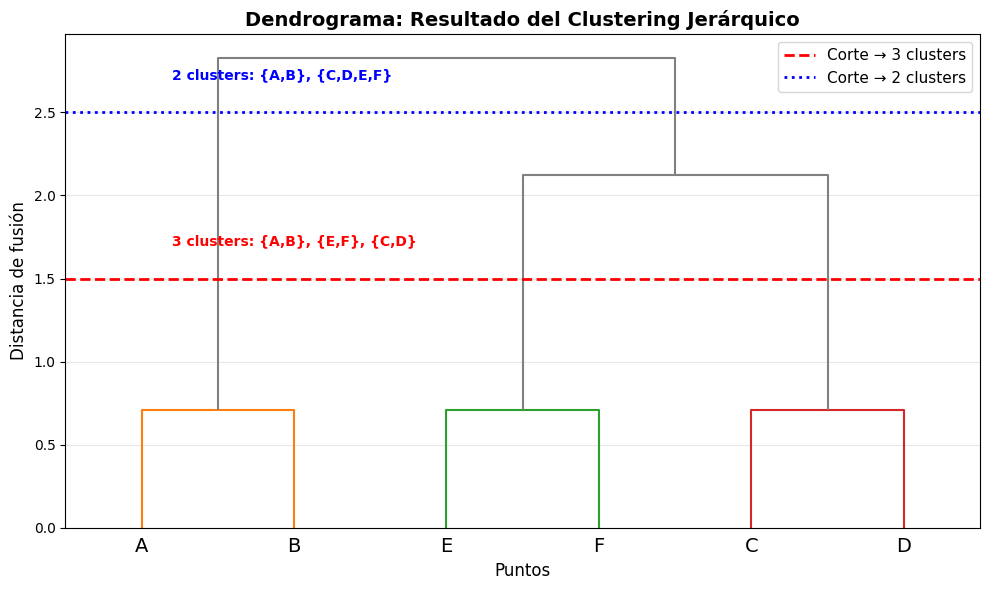

Lectura del dendrograma:
  - La ALTURA de cada U indica la distancia a la que se fusionaron
  - Cortar a altura 1.5 da 3 clusters
  - Cortar a altura 2.5 da 2 clusters
  - El salto más grande indica el número natural de clusters


In [5]:
# Dendrograma con scipy
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
import numpy as np

points = np.array([[1, 1], [1.5, 1.5], [5, 5], [5.5, 5.5], [3, 4], [3.5, 3.5]])
labels = ['A', 'B', 'C', 'D', 'E', 'F']

# Calcular linkage
Z = linkage(points, method='single')

fig, ax = plt.subplots(figsize=(10, 6))
dn = dendrogram(Z, labels=labels, ax=ax, color_threshold=1.5,
                above_threshold_color='gray', leaf_font_size=14)

# Línea de corte
ax.axhline(y=1.5, color='red', linestyle='--', linewidth=2, label='Corte → 3 clusters')
ax.axhline(y=2.5, color='blue', linestyle=':', linewidth=2, label='Corte → 2 clusters')

ax.set_xlabel('Puntos', fontsize=12)
ax.set_ylabel('Distancia de fusión', fontsize=12)
ax.set_title('Dendrograma: Resultado del Clustering Jerárquico', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

# Anotar
ax.text(7, 1.7, '3 clusters: {A,B}, {E,F}, {C,D}', fontsize=10, color='red', fontweight='bold')
ax.text(7, 2.7, '2 clusters: {A,B}, {C,D,E,F}', fontsize=10, color='blue', fontweight='bold')

plt.tight_layout()
plt.show()

print("Lectura del dendrograma:")
print("  - La ALTURA de cada U indica la distancia a la que se fusionaron")
print("  - Cortar a altura 1.5 da 3 clusters")
print("  - Cortar a altura 2.5 da 2 clusters")
print("  - El salto más grande indica el número natural de clusters")

## Implementación con Código

### Funciones

In [6]:
import numpy as np

def euclidean_distance(a, b):
    """Distancia euclidiana entre dos puntos"""
    return np.sqrt(np.sum((a - b) ** 2))


def compute_distance_matrix(X):
    """Calcula la matriz de distancias entre todos los pares de puntos"""
    n = len(X)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            d = euclidean_distance(X[i], X[j])
            D[i, j] = d
            D[j, i] = d
    return D


def cluster_distance(cluster_a, cluster_b, X, method='single'):
    """Distancia entre dos clusters según el criterio de enlace"""
    distances = [euclidean_distance(X[i], X[j]) for i in cluster_a for j in cluster_b]

    if method == 'single':
        return min(distances)
    elif method == 'complete':
        return max(distances)
    elif method == 'average':
        return sum(distances) / len(distances)


def agglomerative_clustering(X, method='single'):
    """
    Clustering jerárquico aglomerativo.
    Retorna: merge_history — lista de (cluster_i, cluster_j, distancia, tamaño)
    """
    n = len(X)
    clusters = {i: [i] for i in range(n)}
    active = set(range(n))
    merge_history = []  # formato compatible con scipy: [idx1, idx2, dist, size]

    for step in range(n - 1):
        # Encontrar par más cercano
        min_dist = np.inf
        merge_pair = None

        active_list = sorted(active)
        for ii, ci in enumerate(active_list):
            for cj in active_list[ii + 1:]:
                d = cluster_distance(clusters[ci], clusters[cj], X, method)
                if d < min_dist:
                    min_dist = d
                    merge_pair = (ci, cj)

        ci, cj = merge_pair

        # Crear nuevo cluster
        new_id = n + step
        clusters[new_id] = clusters[ci] + clusters[cj]
        active.remove(ci)
        active.remove(cj)
        active.add(new_id)

        merge_history.append([ci, cj, min_dist, len(clusters[new_id])])

    return np.array(merge_history)


def get_clusters(merge_history, n_points, n_clusters):
    """Extrae las asignaciones de cluster cortando el dendrograma"""
    n_merges = n_points - n_clusters
    clusters = {i: [i] for i in range(n_points)}

    for step in range(n_merges):
        ci, cj = int(merge_history[step][0]), int(merge_history[step][1])
        new_id = n_points + step
        clusters[new_id] = clusters.get(ci, [ci]) + clusters.get(cj, [cj])
        if ci in clusters:
            del clusters[ci]
        if cj in clusters:
            del clusters[cj]

    # Asignar etiquetas
    labels = np.zeros(n_points, dtype=int)
    for cluster_id, (_, members) in enumerate(clusters.items()):
        for m in members:
            labels[m] = cluster_id

    return labels


print("Funciones definidas: compute_distance_matrix, cluster_distance,")
print("                     agglomerative_clustering, get_clusters")

Funciones definidas: compute_distance_matrix, cluster_distance,
                     agglomerative_clustering, get_clusters


In [7]:
import numpy as np

# Test con los datos de ejemplo
points = np.array([[1, 1], [1.5, 1.5], [5, 5], [5.5, 5.5], [3, 4], [3.5, 3.5]])

merge_hist = agglomerative_clustering(points, method='single')

print("Historial de fusiones (single linkage):")
print(f"{'Paso':>4} | {'Cluster i':>10} | {'Cluster j':>10} | {'Distancia':>10} | {'Tamaño':>7}")
print("-" * 55)
for i, (ci, cj, d, s) in enumerate(merge_hist):
    print(f"{i+1:4d} | {int(ci):10d} | {int(cj):10d} | {d:10.4f} | {int(s):7d}")

# Obtener 3 clusters
cluster_labels = get_clusters(merge_hist, len(points), n_clusters=3)
print(f"\nAsignaciones con 3 clusters: {cluster_labels}")
labels_name = ['A', 'B', 'C', 'D', 'E', 'F']
for i in range(3):
    members = [labels_name[j] for j in range(len(points)) if cluster_labels[j] == i]
    print(f"  Cluster {i}: {members}")

Historial de fusiones (single linkage):
Paso |  Cluster i |  Cluster j |  Distancia |  Tamaño
-------------------------------------------------------
   1 |          0 |          1 |     0.7071 |       2
   2 |          2 |          3 |     0.7071 |       2
   3 |          4 |          5 |     0.7071 |       2
   4 |          7 |          8 |     2.1213 |       4
   5 |          6 |          9 |     2.8284 |       6

Asignaciones con 3 clusters: [0 0 1 1 2 2]
  Cluster 0: ['A', 'B']
  Cluster 1: ['C', 'D']
  Cluster 2: ['E', 'F']


### Clase

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


class HierarchicalClustering:
    """
    Clustering Jerárquico Aglomerativo desde cero.
    Soporta: single, complete, average linkage.
    """
    def __init__(self, n_clusters=2, linkage='single'):
        self.n_clusters = n_clusters
        self.linkage = linkage
        self.merge_history = None
        self.labels_ = None
        self.X_ = None

    def _distance(self, a, b):
        return np.sqrt(np.sum((a - b) ** 2))

    def _cluster_distance(self, cluster_a, cluster_b):
        """Distancia entre dos clusters según el criterio de enlace"""
        dists = [self._distance(self.X_[i], self.X_[j])
                 for i in cluster_a for j in cluster_b]
        if self.linkage == 'single':
            return min(dists)
        elif self.linkage == 'complete':
            return max(dists)
        elif self.linkage == 'average':
            return sum(dists) / len(dists)

    def fit(self, X):
        """Ejecuta el clustering jerárquico aglomerativo"""
        self.X_ = np.array(X)
        n = len(X)
        clusters = {i: [i] for i in range(n)}
        active = set(range(n))
        self.merge_history = []

        for step in range(n - 1):
            min_dist = np.inf
            merge_pair = None

            active_list = sorted(active)
            for ii, ci in enumerate(active_list):
                for cj in active_list[ii + 1:]:
                    d = self._cluster_distance(clusters[ci], clusters[cj])
                    if d < min_dist:
                        min_dist = d
                        merge_pair = (ci, cj)

            ci, cj = merge_pair
            new_id = n + step
            clusters[new_id] = clusters[ci] + clusters[cj]
            active.remove(ci)
            active.remove(cj)
            active.add(new_id)

            self.merge_history.append([ci, cj, min_dist, len(clusters[new_id])])

        # Asignar labels con n_clusters
        self.labels_ = self._cut_tree(n, self.n_clusters, clusters)
        return self

    def _cut_tree(self, n_points, n_clusters, all_clusters=None):
        """Corta el dendrograma para obtener n_clusters"""
        n_merges = n_points - n_clusters
        clusters = {i: [i] for i in range(n_points)}

        for step in range(n_merges):
            ci, cj = int(self.merge_history[step][0]), int(self.merge_history[step][1])
            new_id = n_points + step
            clusters[new_id] = clusters.get(ci, [ci]) + clusters.get(cj, [cj])
            if ci in clusters:
                del clusters[ci]
            if cj in clusters:
                del clusters[cj]

        labels = np.zeros(n_points, dtype=int)
        for cluster_id, (_, members) in enumerate(clusters.items()):
            for m in members:
                labels[m] = cluster_id
        return labels

    def plot_dendrogram(self, labels=None, title=None):
        """Dibuja el dendrograma usando scipy para la visualización"""
        from scipy.cluster.hierarchy import dendrogram

        Z = np.array(self.merge_history)
        fig, ax = plt.subplots(figsize=(10, 6))

        # Determinar altura de corte
        n_merges = len(self.X_) - self.n_clusters
        if n_merges > 0 and n_merges <= len(Z):
            cut_height = (Z[n_merges - 1][2] + Z[min(n_merges, len(Z)-1)][2]) / 2
        else:
            cut_height = Z[-1][2] * 1.1

        dendrogram(Z, labels=labels, ax=ax, color_threshold=cut_height,
                   above_threshold_color='gray', leaf_font_size=11)

        ax.axhline(y=cut_height, color='red', linestyle='--', linewidth=2,
                   label=f'Corte → {self.n_clusters} clusters')

        ax.set_xlabel('Puntos', fontsize=12)
        ax.set_ylabel('Distancia de fusión', fontsize=12)
        ax.set_title(title or f'Dendrograma ({self.linkage} linkage, {self.n_clusters} clusters)',
                     fontsize=13, fontweight='bold')
        ax.legend(fontsize=11)
        ax.grid(True, alpha=0.3, axis='y')
        plt.tight_layout()
        plt.show()

    def plot_clusters(self, title=None):
        """Grafica los clusters (solo 2D)"""
        if self.X_.shape[1] != 2:
            print("plot_clusters solo funciona con datos 2D")
            return

        colors = ['#e74c3c', '#3498db', '#27ae60', '#f39c12', '#9b59b6',
                  '#1abc9c', '#e67e22', '#2c3e50']

        plt.figure(figsize=(8, 6))
        for k in range(self.n_clusters):
            mask = self.labels_ == k
            c = colors[k % len(colors)]
            plt.scatter(self.X_[mask, 0], self.X_[mask, 1], c=c, s=80,
                       edgecolors='k', label=f'Cluster {k}', zorder=5)

        plt.xlabel('$x_1$', fontsize=12)
        plt.ylabel('$x_2$', fontsize=12)
        plt.title(title or f'Clustering Jerárquico ({self.linkage}, k={self.n_clusters})',
                  fontsize=13, fontweight='bold')
        plt.legend(fontsize=10)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

In [9]:
from sklearn import datasets
import numpy as np

# Dataset: make_blobs
X, y_true = datasets.make_blobs(n_samples=60, centers=3, cluster_std=1.0, random_state=42)

# Entrenar con single linkage
model = HierarchicalClustering(n_clusters=3, linkage='single')
model.fit(X)

print(f"Linkage: {model.linkage}")
print(f"Clusters encontrados: {len(np.unique(model.labels_))}")
for k in range(3):
    print(f"  Cluster {k}: {np.sum(model.labels_ == k)} puntos")

Linkage: single
Clusters encontrados: 3
  Cluster 0: 20 puntos
  Cluster 1: 20 puntos
  Cluster 2: 20 puntos


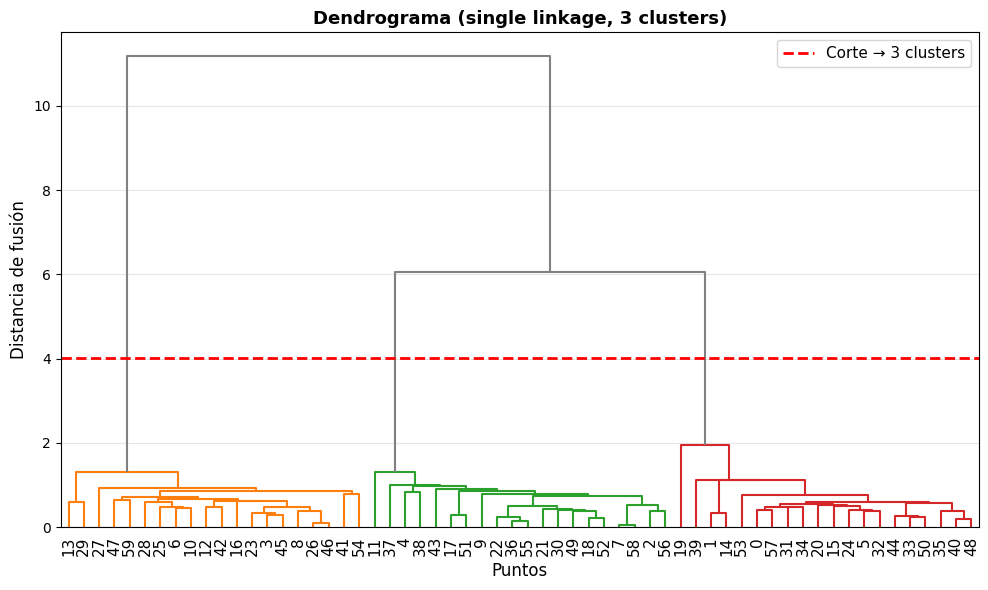

In [10]:
# Dendrograma
model.plot_dendrogram()

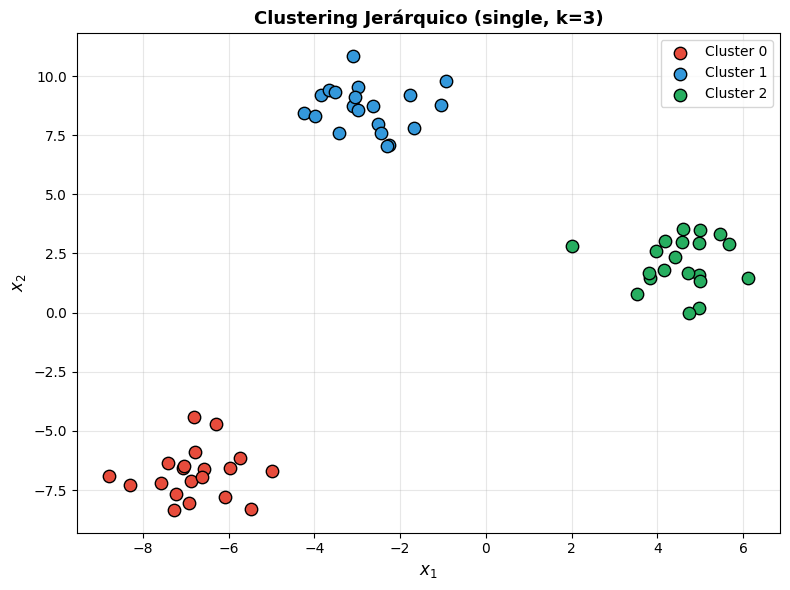

In [11]:
# Clusters en 2D
model.plot_clusters()

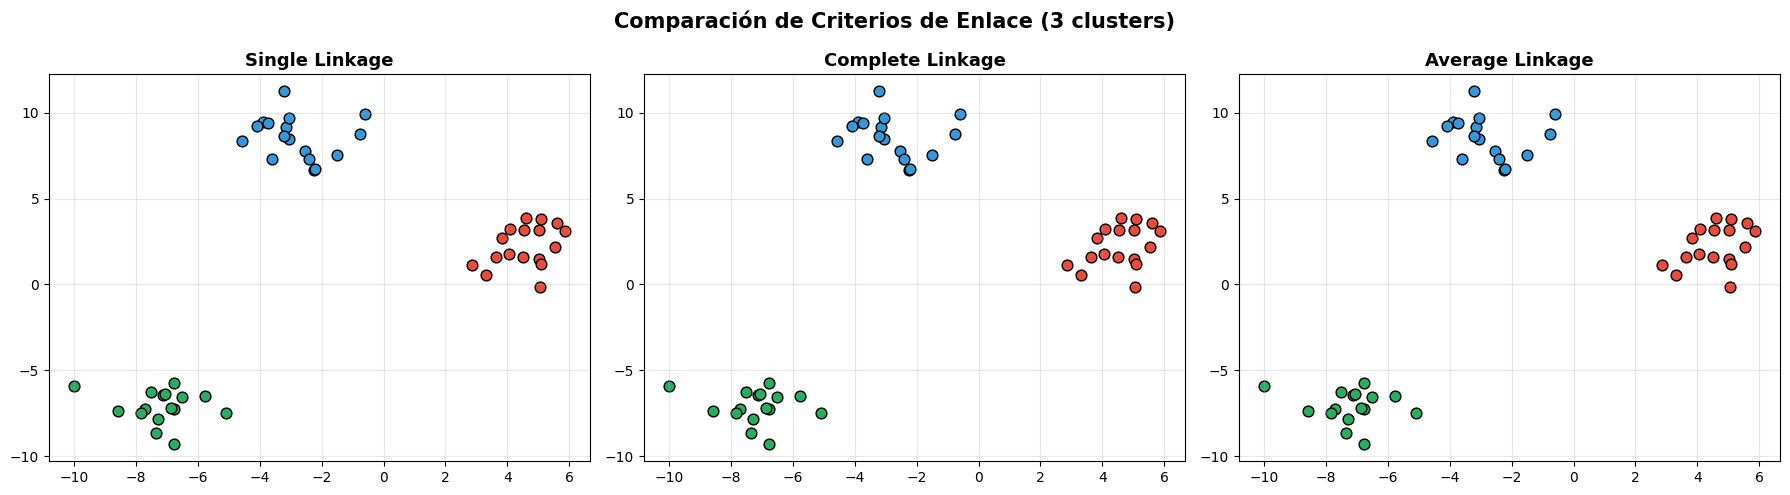

In [12]:
# Comparar los 3 criterios de enlace
from sklearn import datasets
import numpy as np
import matplotlib.pyplot as plt

X, y_true = datasets.make_blobs(n_samples=50, centers=3, cluster_std=1.2, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#e74c3c', '#3498db', '#27ae60', '#f39c12', '#9b59b6']

for ax, method in zip(axes, ['single', 'complete', 'average']):
    m = HierarchicalClustering(n_clusters=3, linkage=method)
    m.fit(X)

    for k in range(3):
        mask = m.labels_ == k
        ax.scatter(X[mask, 0], X[mask, 1], c=colors[k], s=60, edgecolors='k')

    ax.set_title(f'{method.capitalize()} Linkage', fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3)

plt.suptitle('Comparación de Criterios de Enlace (3 clusters)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

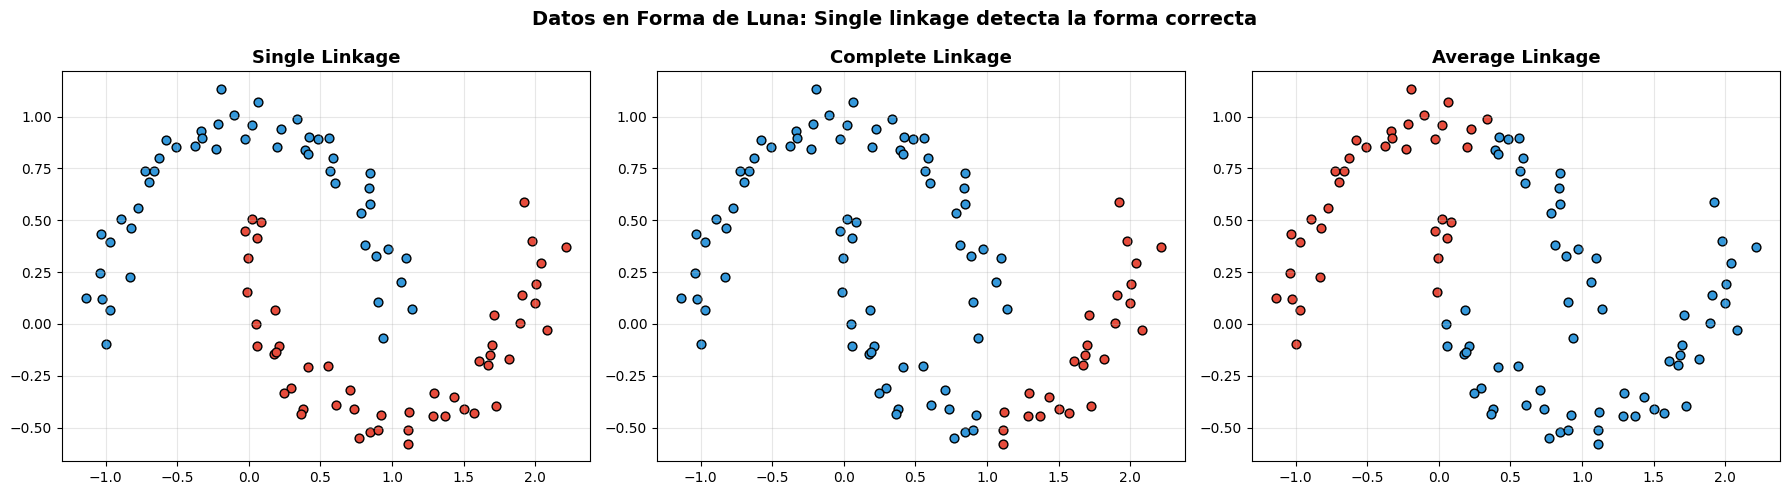

Single linkage: ✓ Detecta clusters no esféricos (formas arbitrarias)
Complete/Average: ✗ Asumen clusters compactos, fallan con formas elongadas


In [13]:
# Caso donde single linkage falla: efecto cadena
from sklearn import datasets
import numpy as np
import matplotlib.pyplot as plt

# Datos en forma de lunas (no esféricos)
X_moons, y_moons = datasets.make_moons(n_samples=100, noise=0.08, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#e74c3c', '#3498db']

for ax, method in zip(axes, ['single', 'complete', 'average']):
    m = HierarchicalClustering(n_clusters=2, linkage=method)
    m.fit(X_moons)

    for k in range(2):
        mask = m.labels_ == k
        ax.scatter(X_moons[mask, 0], X_moons[mask, 1], c=colors[k], s=40, edgecolors='k')

    ax.set_title(f'{method.capitalize()} Linkage', fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3)

plt.suptitle('Datos en Forma de Luna: Single linkage detecta la forma correcta',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Single linkage: ✓ Detecta clusters no esféricos (formas arbitrarias)")
print("Complete/Average: ✗ Asumen clusters compactos, fallan con formas elongadas")

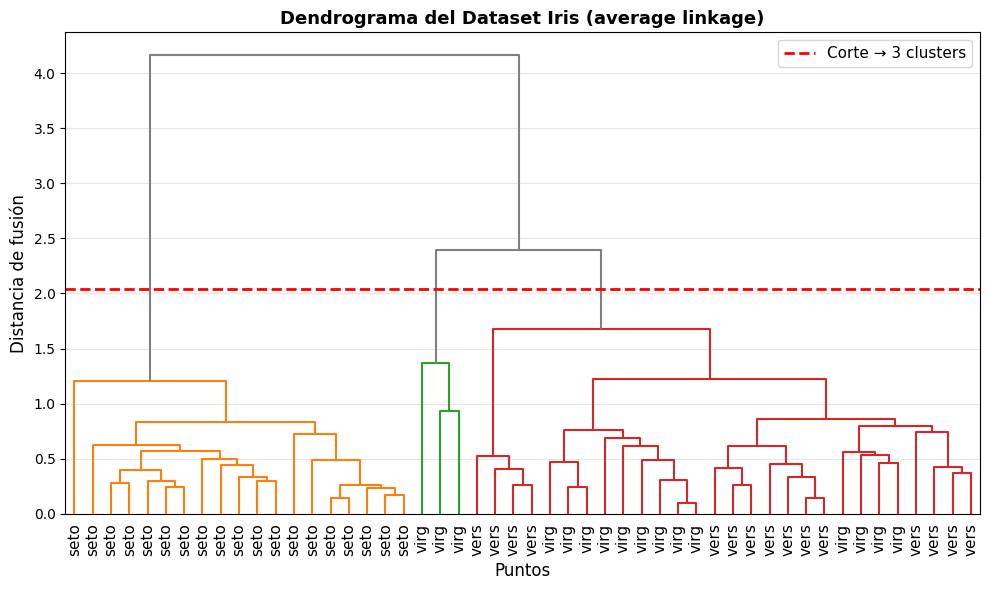

In [14]:
# Dataset Iris: dendrograma + clusters
from sklearn import datasets
import numpy as np

iris = datasets.load_iris()
X_iris = iris.data
y_iris = iris.target

# Usar un subconjunto (por velocidad)
np.random.seed(42)
idx = np.random.choice(len(X_iris), 50, replace=False)
X_sub = X_iris[idx]
y_sub = y_iris[idx]

model_iris = HierarchicalClustering(n_clusters=3, linkage='average')
model_iris.fit(X_sub)

# Dendrograma
labels_iris = [iris.target_names[y_sub[i]][:4] for i in range(len(X_sub))]
model_iris.plot_dendrogram(labels=labels_iris, title='Dendrograma del Dataset Iris (average linkage)')

Adjusted Rand Index (vs etiquetas reales): 0.6041
  (1.0 = perfecto, 0.0 = aleatorio)


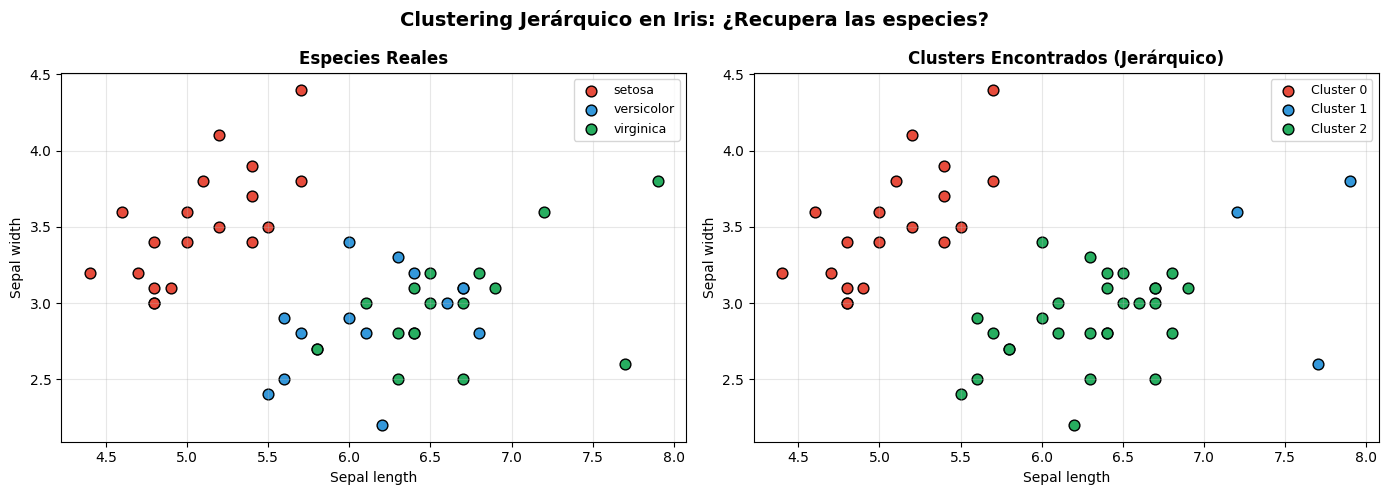

In [15]:
# Comparar con la verdad (Iris tiene 3 especies)
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(y_sub, model_iris.labels_)
print(f"Adjusted Rand Index (vs etiquetas reales): {ari:.4f}")
print(f"  (1.0 = perfecto, 0.0 = aleatorio)")

# Visualizar con las dos primeras features
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#e74c3c', '#3498db', '#27ae60']
species = iris.target_names

# Panel 1: Clusters reales
for k in range(3):
    mask = y_sub == k
    axes[0].scatter(X_sub[mask, 0], X_sub[mask, 1], c=colors[k], s=60,
                   edgecolors='k', label=species[k])
axes[0].set_title('Especies Reales', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)
axes[0].set_xlabel('Sepal length')
axes[0].set_ylabel('Sepal width')

# Panel 2: Clusters encontrados
for k in range(3):
    mask = model_iris.labels_ == k
    axes[1].scatter(X_sub[mask, 0], X_sub[mask, 1], c=colors[k], s=60,
                   edgecolors='k', label=f'Cluster {k}')
axes[1].set_title('Clusters Encontrados (Jerárquico)', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)
axes[1].set_xlabel('Sepal length')
axes[1].set_ylabel('Sepal width')

plt.suptitle('Clustering Jerárquico en Iris: ¿Recupera las especies?', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [16]:
# Resumen
print("="*70)
print("RESUMEN: CLUSTERING JERÁRQUICO")
print("="*70)
print()
print("┌─────────────────────────────────────────────────────────────────────┐")
print("│ Clustering Jerárquico Aglomerativo                                  │")
print("│   • Construye una jerarquía de clusters (dendrograma)                │")
print("│   • No necesita especificar k de antemano                            │")
print("│   • Fusiona iterativamente los clusters más cercanos                 │")
print("│   • Cortar el dendrograma da el número deseado de clusters           │")
print("├─────────────────────────────────────────────────────────────────────┤")
print("│ Criterios de Enlace                                                 │")
print("│   • Single: min distancia → detecta formas arbitrarias              │")
print("│   • Complete: max distancia → clusters compactos                    │")
print("│   • Average: promedio → compromiso robusto                          │")
print("│   • Ward: min varianza → clusters de tamaños similares              │")
print("├─────────────────────────────────────────────────────────────────────┤")
print("│ Ventajas vs Desventajas                                             │")
print("│   ✓ No requiere k a priori (el dendrograma muestra todo)             │")
print("│   ✓ Produce una jerarquía interpretable                              │")
print("│   ✓ Determinista (sin inicialización aleatoria)                      │")
print("│   ✗ Complejidad O(n³) — lento para datasets grandes                 │")
print("│   ✗ No puede deshacer fusiones (greedy)                              │")
print("│   ✗ Sensible a outliers (especialmente complete linkage)              │")
print("└─────────────────────────────────────────────────────────────────────┘")

RESUMEN: CLUSTERING JERÁRQUICO

┌─────────────────────────────────────────────────────────────────────┐
│ Clustering Jerárquico Aglomerativo                                  │
│   • Construye una jerarquía de clusters (dendrograma)                │
│   • No necesita especificar k de antemano                            │
│   • Fusiona iterativamente los clusters más cercanos                 │
│   • Cortar el dendrograma da el número deseado de clusters           │
├─────────────────────────────────────────────────────────────────────┤
│ Criterios de Enlace                                                 │
│   • Single: min distancia → detecta formas arbitrarias              │
│   • Complete: max distancia → clusters compactos                    │
│   • Average: promedio → compromiso robusto                          │
│   • Ward: min varianza → clusters de tamaños similares              │
├─────────────────────────────────────────────────────────────────────┤
│ Ventajas vs Desventajas   